# Iteration 0 Baselines: Logistic Regression and Linear SVM on Generic summary

compares two simple subject-wise baselines:
- logistic regression
- linear SVM

It does four things:
1. Loads the driving-only IDD scenarios and the fixed participant folds.
2. Converts each 30-second scenario window into one feature vector using summary statistics over gaze and vehicle signals.
3. Trains both models with subject-wise cross-validation.
4. Reports UAR, macro precision, macro F1, confusion matrices, and per-class metrics.

This is a sanity-check baseline stage, not the final model.

In [1]:
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "dataset" / "README.md").exists():
            return candidate
    raise FileNotFoundError("Could not find the project root containing dataset/README.md.")

root = find_project_root(Path.cwd().resolve())
dbm_repo = root / "dataset"
data_dir = root / "data" / "IDD"

# These baselines only use tabular signals, so `no-video` is enough.
# `only-scaled-rgb-video` also works because it includes the same tabular files.
version = "no-video"
# version = "only-scaled-rgb-video"

target_fps = 10
chunk_duration_s = 30.0
chunks_per_scenario = 1
rebuild_feature_table = False
progress_every = 25

artifact_dir = root / "artifacts" / "logreg_baseline"
artifact_dir.mkdir(parents=True, exist_ok=True)
feature_table_path = artifact_dir / "scenario_window_features.pkl"

root

WindowsPath('C:/projects/DriverStateNet')

In [2]:
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

for name in list(sys.modules):
    if name == "data" or name.startswith("data."):
        sys.modules.pop(name, None)
    if name == "hail_datasets" or name.startswith("hail_datasets."):
        sys.modules.pop(name, None)

import src.classical_baseline as classical_baseline
import src.data_bootstrap as data_bootstrap
import src

importlib.reload(classical_baseline)
importlib.reload(data_bootstrap)
importlib.reload(src)

from src import (
    LABEL_ORDER,
    build_inspection_dataset,
    build_scenario_feature_table,
    build_scenario_manifest,
    ensure_processed_dataset,
    feature_columns_from_table,
    run_fixed_fold_linear_svm_baseline,
    run_fixed_fold_logistic_baseline,
)

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
np.set_printoptions(suppress=True)

## 1. Load the Dataset and Manifest

The baselines only need the tabular modalities.
They still use the same scenario definitions and the same fixed subject folds as the main project.

In [3]:
processed_root = ensure_processed_dataset(
    dbm_repo=dbm_repo,
    processed_root=data_dir,
    version=version,
    download_if_missing=False,
    prompt_for_license=False,
)

manifest_path = root / "artifacts" / "bootstrap" / "scenario_manifest.csv"
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    print(f"Loaded manifest from {manifest_path}")
else:
    manifest = build_scenario_manifest(
        dbm_repo=dbm_repo,
        processed_root=processed_root,
        scenario_name_filter=r"driving/[0-9].*",
    )
    manifest_path = artifact_dir / "scenario_manifest.csv"
    manifest.to_csv(manifest_path, index=False)
    print(f"Built and saved manifest to {manifest_path}")

summary = pd.DataFrame(
    {
        "num_scenarios": [len(manifest)],
        "num_participants": [manifest["participant_name"].nunique()],
        "num_folds": [manifest["fixed_fold"].nunique()],
        "num_labels": [manifest["impairment_label"].nunique()],
    }
)

display(summary)
display(manifest.head())

Loaded manifest from C:\projects\DriverStateNet\artifacts\bootstrap\scenario_manifest.csv


,num_scenarios,num_participants,num_folds,num_labels
0,371,52,5,4


,participant_name,scenario_name,scenario_code,round,cognitive_task,is_cd,intoxicated,impairment_label,label_id,fixed_fold,duration_s,experiment_version,number_all_crashes,number_hazard_crashes,has_any_crash,has_hazard_crash,level_0,index,scenario_index,scenario_path,start_time,end_time,duration_frames,anomalies
0,7224,driving/2b-vehicle_door_open_hazard,2b,R1,no_task,False,False,baseline,0,3,225.087415,2,0,0,False,False,0,8,8,R1/driving/2b-vehicle_door_open_hazard/no_task,1724951349597690691,1724951574685105194,2251,[]
1,7224,driving/8a-pedestrian_pop_out,8a,R1,nback_task,True,False,cognitive_distraction,1,3,233.037594,2,0,0,False,False,1,9,9,R1/driving/8a-pedestrian_pop_out/nback_task,1724951730039958478,1724951963077552196,2331,[]
2,7224,driving/6e-vehicle_run_red_light,6e,R1,no_task,False,False,baseline,0,3,215.593040,2,1,-1,True,False,2,10,10,R1/driving/6e-vehicle_run_red_light/no_task,1724952075862407325,1724952291455447480,2156,[]
3,7224,driving/3c-pedestrian_pop_out,3c,R1,statement_task,True,False,cognitive_distraction,1,3,247.924779,2,2,0,True,False,3,11,11,R1/driving/3c-pedestrian_pop_out/statement_task,1724952395016534983,1724952642941313835,2480,[]
4,7224,driving/5-vehicle_run_stop,5,R2,no_task,False,False,baseline,0,3,265.452630,2,0,-1,False,False,4,17,17,R2/driving/5-vehicle_run_stop/no_task,1724953707364812708,1724953972817442291,2655,[]


In [4]:
inspection_dataset = build_inspection_dataset(
    dbm_repo=dbm_repo,
    processed_root=processed_root,
    scenario_name_filter=r"driving/[0-9].*",
    chunk_strategy="end",
    chunk_duration_s=chunk_duration_s,
    chunks_per_scenario=chunks_per_scenario,
    chunk_end_offset_s=0.0,
    include_video=False,
)

print(f"Dataset length: {len(inspection_dataset)}")

chunk_fps not specified - using max feature frame rate of 60.
Constructed dataset contains 52 participants, 371 scenarios, and 371 chunks.
Dataset length: 371


## 2. Build One Feature Vector per Scenario Window

For each 30-second window we summarize the aligned time series into simple statistics:
- mean, std, min, max for the filled signal values
- observation rate for each feature mask
- mean and max of the time-delta features

This gives us cheap classical baselines without sequence modeling.

In [5]:
if feature_table_path.exists() and not rebuild_feature_table:
    feature_table = pd.read_pickle(feature_table_path)
    print(f"Loaded cached feature table from {feature_table_path}")
else:
    feature_table = build_scenario_feature_table(
        inspection_dataset,
        manifest=manifest,
        target_fps=target_fps,
        progress_every=progress_every,
    )
    feature_table.to_pickle(feature_table_path)
    feature_table.to_csv(artifact_dir / "scenario_window_features.csv", index=False)
    print(f"Saved feature table to {feature_table_path}")

feature_columns = feature_columns_from_table(feature_table)

summary = pd.DataFrame(
    {
        "num_rows": [len(feature_table)],
        "num_feature_columns": [len(feature_columns)],
        "num_participants": [feature_table["participant_name"].nunique()],
        "num_folds": [feature_table["fixed_fold"].nunique()],
    }
)

display(summary)
display(
    feature_table[
        [
            "participant_name",
            "scenario_name",
            "round",
            "cognitive_task",
            "impairment_label",
            "fixed_fold",
        ]
    ].head()
)

Loaded cached feature table from C:\projects\DriverStateNet\artifacts\logreg_baseline\scenario_window_features.pkl


,num_rows,num_feature_columns,num_participants,num_folds
0,371,196,52,5


,participant_name,scenario_name,round,cognitive_task,impairment_label,fixed_fold
0,7224,driving/2b-vehicle_door_open_hazard,R1,no_task,baseline,3
1,7224,driving/8a-pedestrian_pop_out,R1,nback_task,cognitive_distraction,3
2,7224,driving/6e-vehicle_run_red_light,R1,no_task,baseline,3
3,7224,driving/3c-pedestrian_pop_out,R1,statement_task,cognitive_distraction,3
4,7224,driving/5-vehicle_run_stop,R2,no_task,baseline,3


impairment_label,baseline,cognitive_distraction,alcohol_intoxication,combined
fixed_fold,,,,
0,35,32,8,7
1,28,29,7,8
2,25,29,8,8
3,27,28,8,8
4,33,29,6,8


C:\Users\FarzadA\AppData\Local\Temp\ipykernel_7772\4224180325.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, ax=axes[1], palette="deep")


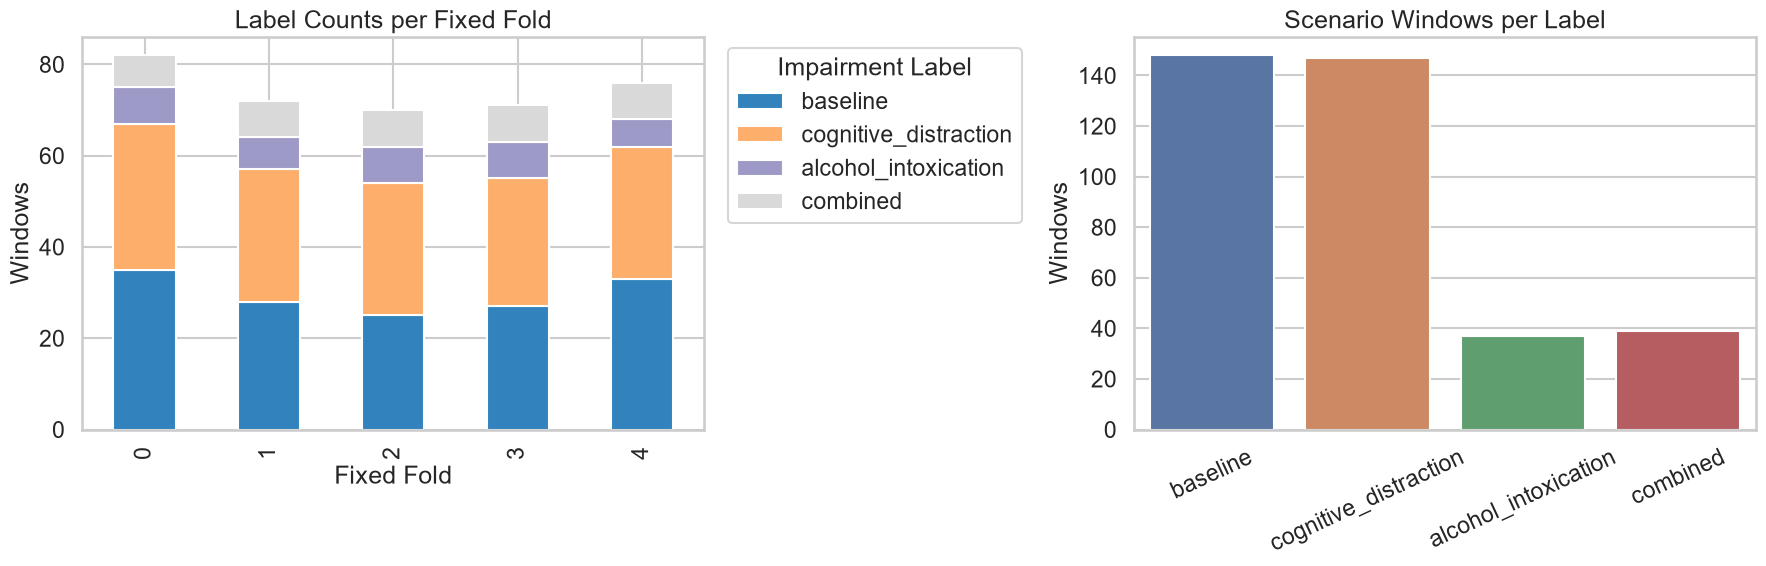

In [6]:
fold_label_counts = pd.crosstab(
    feature_table["fixed_fold"],
    feature_table["impairment_label"],
).reindex(columns=LABEL_ORDER, fill_value=0)

display(fold_label_counts)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

fold_label_counts.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20c")
axes[0].set_title("Label Counts per Fixed Fold")
axes[0].set_xlabel("Fixed Fold")
axes[0].set_ylabel("Windows")
axes[0].legend(title="Impairment Label", bbox_to_anchor=(1.02, 1), loc="upper left")

label_counts = feature_table["impairment_label"].value_counts().reindex(LABEL_ORDER, fill_value=0)
sns.barplot(x=label_counts.index, y=label_counts.values, ax=axes[1], palette="deep")
axes[1].set_title("Scenario Windows per Label")
axes[1].set_xlabel("")
axes[1].set_ylabel("Windows")
axes[1].tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(artifact_dir / "label_balance.png", dpi=150, bbox_inches="tight")

## 3. Train and Compare the Classical Baselines

Evaluation rule:
- train on 4 participant folds
- test on the held-out fold
- repeat for all folds
- report UAR as the main metric

We also report macro precision and macro F1 because the classes are imbalanced.

In [7]:
logistic_regression = run_fixed_fold_logistic_baseline(
    feature_table,
    feature_columns=feature_columns,
    label_column="impairment_label",
    fold_column="fixed_fold",
    labels=LABEL_ORDER,
    c_value=1.0,
    class_weight="balanced",
    max_iter=2000,
)

linear_svm = run_fixed_fold_linear_svm_baseline(
    feature_table,
    feature_columns=feature_columns,
    label_column="impairment_label",
    fold_column="fixed_fold",
    labels=LABEL_ORDER,
    c_value=1.0,
    class_weight="balanced",
    max_iter=4000,
)

baselines = {
    "logistic_regression": logistic_regression,
    "linear_svm": linear_svm,
}

def save_baseline_outputs(model_name: str, result: dict) -> None:
    model_dir = artifact_dir / model_name
    model_dir.mkdir(parents=True, exist_ok=True)
    result["fold_metrics"].to_csv(model_dir / "fold_metrics.csv", index=False)
    result["predictions"].to_csv(model_dir / "predictions.csv", index=False)
    result["overall_confusion"].to_csv(model_dir / "overall_confusion.csv")
    result["per_class_report"].to_csv(model_dir / "per_class_report.csv")
    result["overall_metrics"].to_csv(model_dir / "overall_metrics.csv", header=["value"])

for model_name, result in baselines.items():
    save_baseline_outputs(model_name, result)

overall_comparison = pd.DataFrame(
    [result["overall_metrics"].to_dict() for result in baselines.values()]
).set_index("model_name")

fold_metrics = pd.concat(
    [result["fold_metrics"] for result in baselines.values()],
    ignore_index=True,
)

per_class_report = pd.concat(
    [
        result["per_class_report"].reset_index().rename(columns={"index": "label"}).assign(model_name=model_name)
        for model_name, result in baselines.items()
    ],
    ignore_index=True,
)

overall_comparison.to_csv(artifact_dir / "model_comparison.csv")
per_class_report.to_csv(artifact_dir / "per_class_report_all_models.csv", index=False)

display(overall_comparison)
display(fold_metrics)
display(per_class_report)

,uar,precision_macro,recall_macro,f1_macro,accuracy,num_samples,num_features,num_folds
model_name,,,,,,,,
logistic_regression,0.369665,0.365435,0.369665,0.362744,0.447439,371,196,5
linear_svm,0.376076,0.368688,0.376076,0.368665,0.450135,371,196,5


,model_name,fixed_fold,num_train,num_test,uar,precision_macro,recall_macro,f1_macro,accuracy
0,logistic_regression,0,289,82,0.367411,0.355180,0.367411,0.351752,0.426829
1,logistic_regression,1,299,72,0.442118,0.413773,0.442118,0.417654,0.472222
2,logistic_regression,2,301,70,0.335819,0.363203,0.335819,0.337803,0.414286
3,logistic_regression,3,300,71,0.332176,0.316267,0.332176,0.319026,0.478873
4,logistic_regression,4,295,76,0.396062,0.369925,0.396062,0.359790,0.447368
5,linear_svm,0,289,82,0.336830,0.336012,0.336830,0.321351,0.414634
6,linear_svm,1,299,72,0.451355,0.429412,0.451355,0.432049,0.486111
7,linear_svm,2,301,70,0.424181,0.456057,0.424181,0.419929,0.485714
8,linear_svm,3,300,71,0.323578,0.323246,0.323578,0.314560,0.464789
9,linear_svm,4,295,76,0.372290,0.333864,0.372290,0.337218,0.407895


,label,precision,recall,f1,support,model_name
0,baseline,0.566176,0.520270,0.542254,148,logistic_regression
1,cognitive_distraction,0.559055,0.482993,0.518248,147,logistic_regression
2,alcohol_intoxication,0.158730,0.270270,0.200000,37,logistic_regression
3,combined,0.177778,0.205128,0.190476,39,logistic_regression
4,baseline,0.574627,0.520270,0.546099,148,linear_svm
5,cognitive_distraction,0.537879,0.482993,0.508961,147,linear_svm
6,alcohol_intoxication,0.178571,0.270270,0.215054,37,linear_svm
7,combined,0.183673,0.230769,0.204545,39,linear_svm


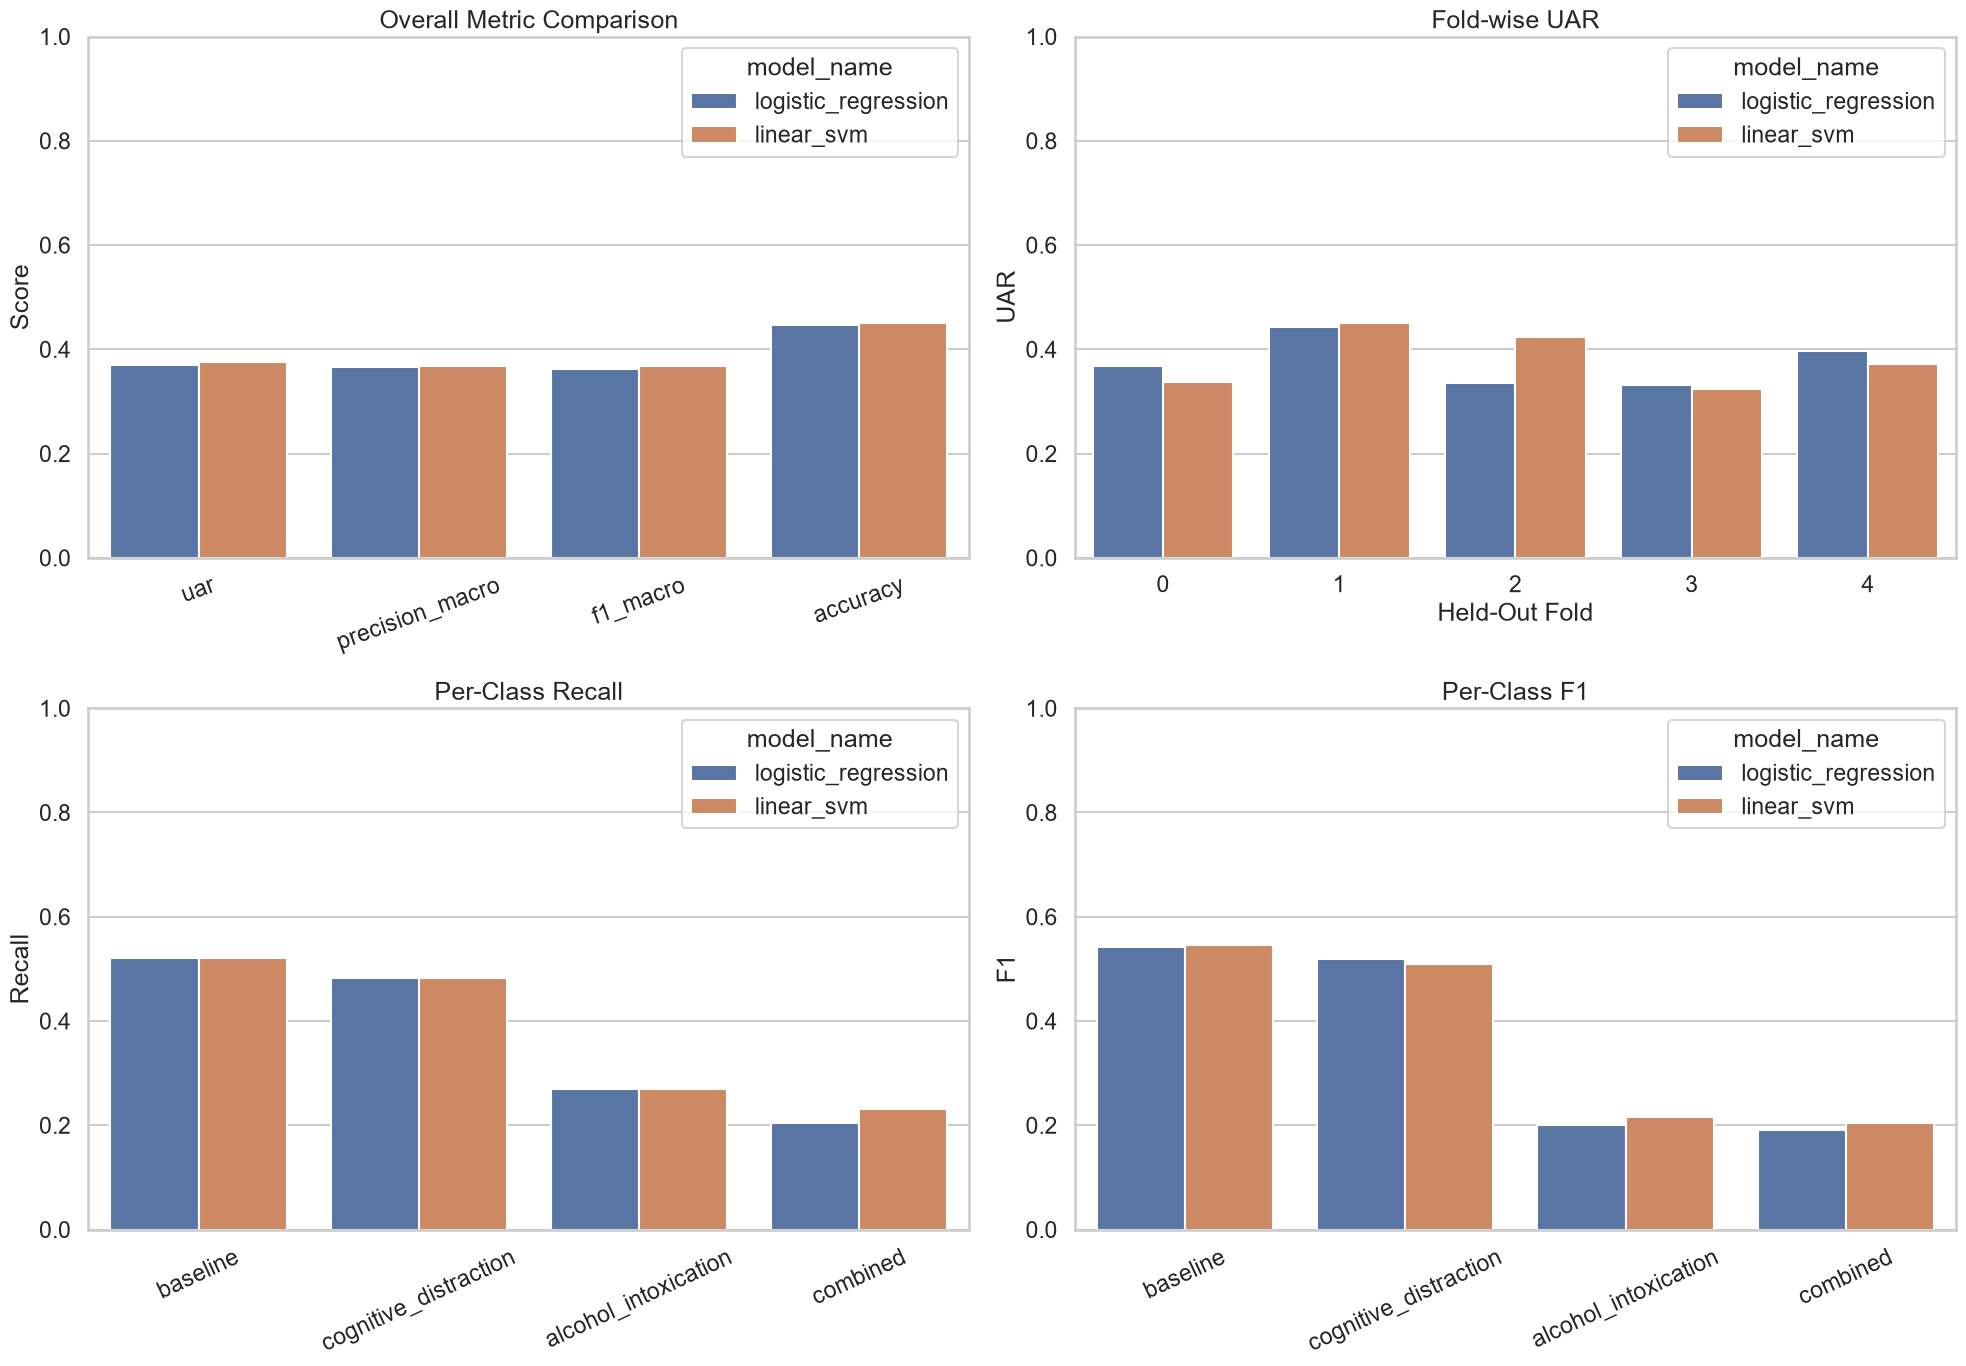

In [8]:
metric_plot = (
    overall_comparison[["uar", "precision_macro", "f1_macro", "accuracy"]]
    .reset_index()
    .melt(id_vars="model_name", var_name="metric", value_name="score")
)

per_class_plot = per_class_report.copy()

fig, axes = plt.subplots(2, 2, figsize=(20, 14))

sns.barplot(data=metric_plot, x="metric", y="score", hue="model_name", ax=axes[0, 0])
axes[0, 0].set_title("Overall Metric Comparison")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Score")
axes[0, 0].set_ylim(0.0, 1.0)
axes[0, 0].tick_params(axis="x", rotation=20)

sns.barplot(data=fold_metrics, x="fixed_fold", y="uar", hue="model_name", ax=axes[0, 1])
axes[0, 1].set_title("Fold-wise UAR")
axes[0, 1].set_xlabel("Held-Out Fold")
axes[0, 1].set_ylabel("UAR")
axes[0, 1].set_ylim(0.0, 1.0)

sns.barplot(data=per_class_plot, x="label", y="recall", hue="model_name", ax=axes[1, 0])
axes[1, 0].set_title("Per-Class Recall")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Recall")
axes[1, 0].set_ylim(0.0, 1.0)
axes[1, 0].tick_params(axis="x", rotation=25)

sns.barplot(data=per_class_plot, x="label", y="f1", hue="model_name", ax=axes[1, 1])
axes[1, 1].set_title("Per-Class F1")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("F1")
axes[1, 1].set_ylim(0.0, 1.0)
axes[1, 1].tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(artifact_dir / "model_comparison_plots.png", dpi=150, bbox_inches="tight")

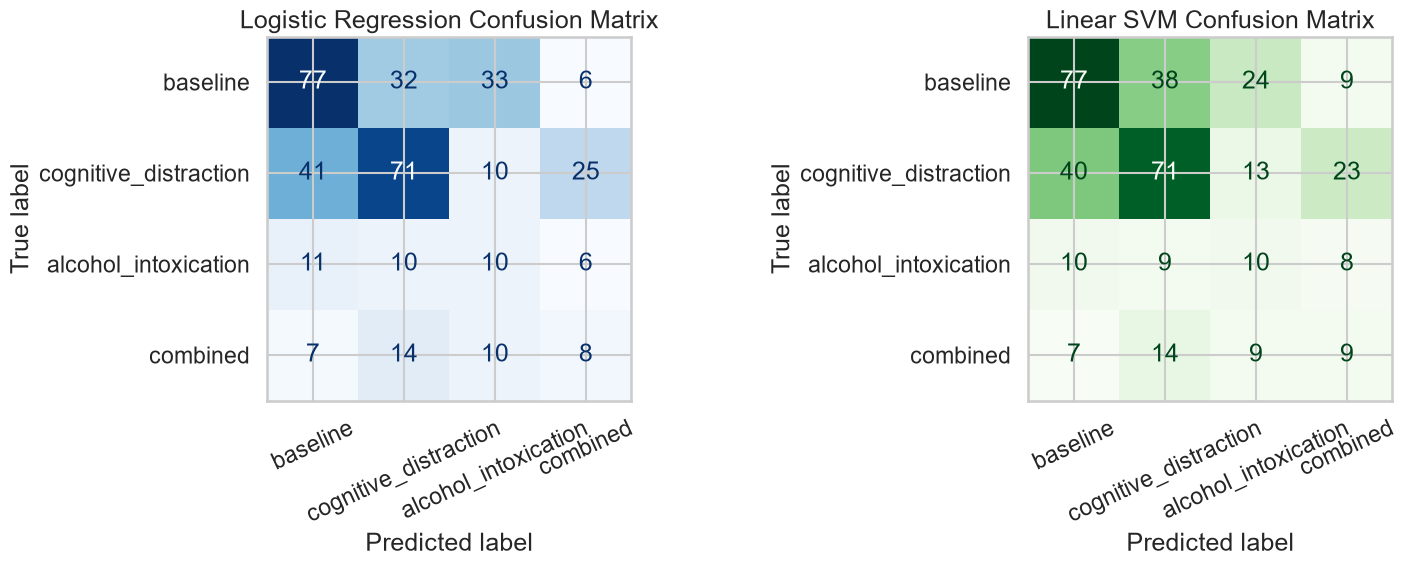

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
logistic_display = ConfusionMatrixDisplay(
    confusion_matrix=logistic_regression["overall_confusion"].to_numpy(),
    display_labels=logistic_regression["overall_confusion"].index.to_list(),
)
logistic_display.plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False,
)
axes[0].set_title("Logistic Regression Confusion Matrix")
axes[0].tick_params(axis="x", rotation=25)

svm_display = ConfusionMatrixDisplay(
    confusion_matrix=linear_svm["overall_confusion"].to_numpy(),
    display_labels=linear_svm["overall_confusion"].index.to_list(),
)
svm_display.plot(
    ax=axes[1],
    cmap="Greens",
    values_format="d",
    colorbar=False,
)
axes[1].set_title("Linear SVM Confusion Matrix")
axes[1].tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(artifact_dir / "confusion_matrices.png", dpi=150, bbox_inches="tight")

In [10]:
for model_name, result in baselines.items():
    print(f"\nTop error pairs for {model_name}")
    errors = result["predictions"].loc[result["predictions"]["true_label"] != result["predictions"]["pred_label"]].copy()
    error_pairs = (
        errors.groupby(["true_label", "pred_label"])
        .size()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )
    display(error_pairs.head(12))


Top error pairs for logistic_regression


,true_label,pred_label,count
7,cognitive_distraction,baseline,41
3,baseline,alcohol_intoxication,33
4,baseline,cognitive_distraction,32
8,cognitive_distraction,combined,25
11,combined,cognitive_distraction,14
0,alcohol_intoxication,baseline,11
9,combined,alcohol_intoxication,10
1,alcohol_intoxication,cognitive_distraction,10
6,cognitive_distraction,alcohol_intoxication,10
10,combined,baseline,7



Top error pairs for linear_svm


,true_label,pred_label,count
7,cognitive_distraction,baseline,40
4,baseline,cognitive_distraction,38
3,baseline,alcohol_intoxication,24
8,cognitive_distraction,combined,23
11,combined,cognitive_distraction,14
6,cognitive_distraction,alcohol_intoxication,13
0,alcohol_intoxication,baseline,10
1,alcohol_intoxication,cognitive_distraction,9
9,combined,alcohol_intoxication,9
5,baseline,combined,9


## 4. Auxiliary Binary Task: Intoxicated vs Not Intoxicated

This is not the main project task, but it is a useful sanity check.
We collapse the labels into:
- `not_intoxicated`: baseline + cognitive_distraction
- `intoxicated`: alcohol_intoxication + combined

intoxication_label,not_intoxicated,intoxicated
fixed_fold,,
0,67,15
1,57,15
2,54,16
3,55,16
4,62,14


<Figure size 800x500 with 0 Axes>

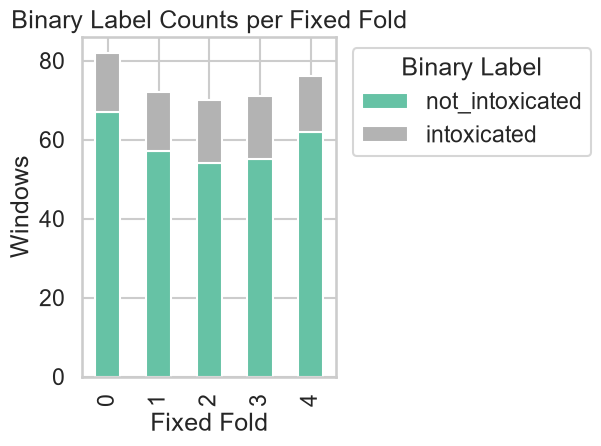

In [11]:
binary_feature_table = feature_table.copy()
binary_feature_table["intoxication_label"] = np.where(
    binary_feature_table["intoxicated"],
    "intoxicated",
    "not_intoxicated",
)
binary_labels = ["not_intoxicated", "intoxicated"]

binary_fold_counts = pd.crosstab(
    binary_feature_table["fixed_fold"],
    binary_feature_table["intoxication_label"],
).reindex(columns=binary_labels, fill_value=0)

display(binary_fold_counts)

plt.figure(figsize=(8, 5))
binary_fold_counts.plot(kind="bar", stacked=True, colormap="Set2")
plt.title("Binary Label Counts per Fixed Fold")
plt.xlabel("Fixed Fold")
plt.ylabel("Windows")
plt.legend(title="Binary Label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(artifact_dir / "binary_label_balance.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
binary_logistic_regression = run_fixed_fold_logistic_baseline(
    binary_feature_table,
    feature_columns=feature_columns,
    label_column="intoxication_label",
    fold_column="fixed_fold",
    labels=binary_labels,
    c_value=1.0,
    class_weight="balanced",
    max_iter=2000,
)

binary_dir = artifact_dir / "binary_intoxication_logreg"
binary_dir.mkdir(parents=True, exist_ok=True)

binary_logistic_regression["fold_metrics"].to_csv(binary_dir / "fold_metrics.csv", index=False)
binary_logistic_regression["predictions"].to_csv(binary_dir / "predictions.csv", index=False)
binary_logistic_regression["overall_confusion"].to_csv(binary_dir / "overall_confusion.csv")
binary_logistic_regression["per_class_report"].to_csv(binary_dir / "classification_report.csv")
binary_logistic_regression["overall_metrics"].to_csv(binary_dir / "overall_metrics.csv", header=["value"])

display(binary_logistic_regression["fold_metrics"])
display(binary_logistic_regression["overall_metrics"].to_frame("value"))
display(binary_logistic_regression["per_class_report"])

,model_name,fixed_fold,num_train,num_test,uar,precision_macro,recall_macro,f1_macro,accuracy
0,logistic_regression,0,289,82,0.584577,0.580492,0.584577,0.582343,0.743902
1,logistic_regression,1,299,72,0.677193,0.634428,0.677193,0.642502,0.722222
2,logistic_regression,2,301,70,0.461806,0.471154,0.461806,0.455782,0.542857
3,logistic_regression,3,300,71,0.471591,0.464689,0.471591,0.466165,0.661972
4,logistic_regression,4,295,76,0.680876,0.635931,0.680876,0.647375,0.750000


,value
model_name,logistic_regression
uar,0.57384
precision_macro,0.561879
recall_macro,0.57384
f1_macro,0.564554
accuracy,0.687332
num_samples,371
num_features,196
num_folds,5


,precision,recall,f1,support
not_intoxicated,0.827839,0.766102,0.795775,295
intoxicated,0.295918,0.381579,0.333333,76


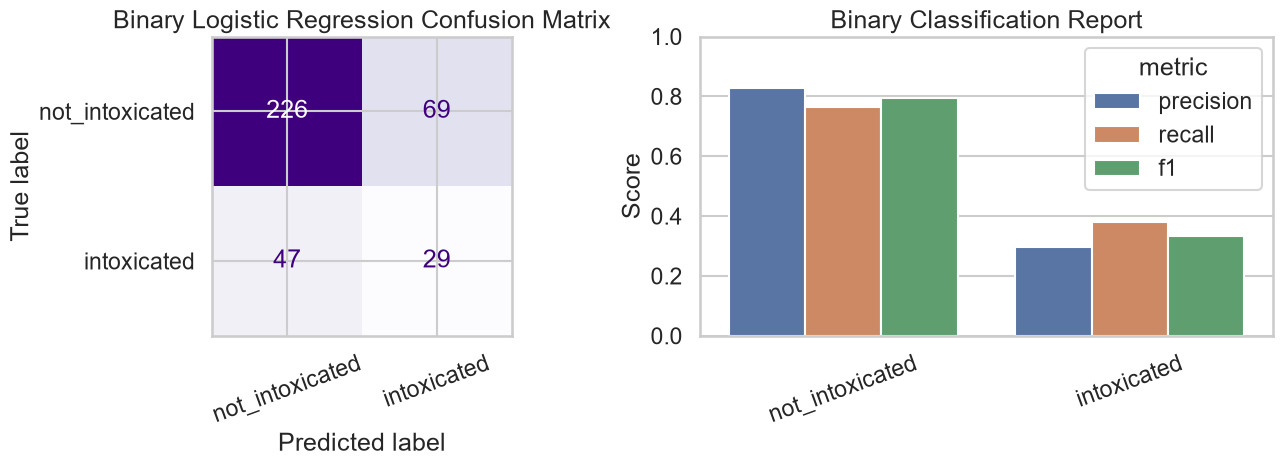

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

binary_display = ConfusionMatrixDisplay(
    confusion_matrix=binary_logistic_regression["overall_confusion"].to_numpy(),
    display_labels=binary_logistic_regression["overall_confusion"].index.to_list(),
)
binary_display.plot(
    ax=axes[0],
    cmap="Purples",
    values_format="d",
    colorbar=False,
)
axes[0].set_title("Binary Logistic Regression Confusion Matrix")
axes[0].tick_params(axis="x", rotation=20)

binary_report_plot = (
    binary_logistic_regression["per_class_report"]
    .reset_index()
    .rename(columns={"index": "label"})
    .melt(id_vars=["label", "support"], value_vars=["precision", "recall", "f1"], var_name="metric", value_name="score")
)
sns.barplot(data=binary_report_plot, x="label", y="score", hue="metric", ax=axes[1])
axes[1].set_title("Binary Classification Report")
axes[1].set_xlabel("")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0.0, 1.0)
axes[1].tick_params(axis="x", rotation=20)

fig.tight_layout()
fig.savefig(binary_dir / "binary_results.png", dpi=150, bbox_inches="tight")